In [1]:
zip_dir= "../dataset/raw/data.zip"
extract_to= "../dataset/preprocessed"

In [2]:
import shutil

shutil.unpack_archive(zip_dir, extract_to)
print("Unpacked")

Unpacked


In [3]:
import os

def get_info(dir_name):
    try:
        if os.path.exists(dir_name):
            return os.listdir(dir_name)
        else:
            return []
    except OSError as e:
        return e

In [4]:
get_info(extract_to)

['Testing', 'Training']

In [5]:
get_info(os.path.join(extract_to, "Testing"))

['glioma', 'meningioma', 'notumor', 'pituitary']

In [6]:
train_data= "../dataset/preprocessed/training"
test_data= "../dataset/preprocessed/testing"

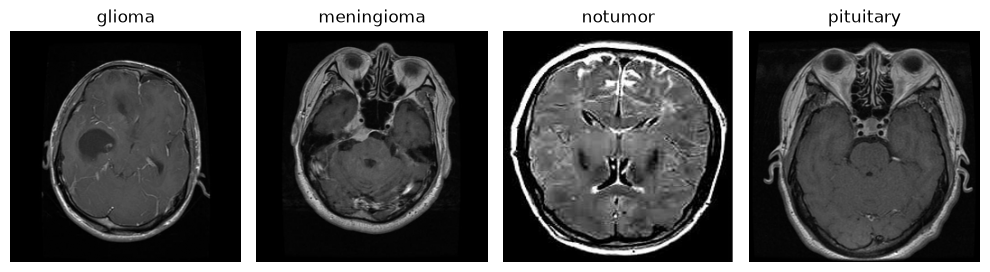

In [26]:
import matplotlib.pyplot as plt
import random
from PIL import Image

plt.figure(figsize=(10, 10))

for i, class_name in enumerate(os.listdir(train_data)):
    class_folder= os.path.join(train_data, class_name)
    random_image= random.choice(os.listdir(class_folder))
    image_path= os.path.join(class_folder, random_image)

    img= Image.open(image_path)
    img= img.resize(size= (256, 256))
    img= img.convert("L")
    plt.subplot(2, 4, i+ 1)
    plt.imshow(img, cmap= "gray")
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
import numpy as np

sizes= []
modes= []

for class_name in os.listdir(train_data):
    sample= os.listdir(os.path.join(train_data,class_name))[:100]
    for image in sample:
        img_path= os.path.join(train_data, class_name, image)
        img= Image.open(img_path)
        sizes.append(img.size)
        modes.append(img.mode)
sizes= np.array(sizes)
print(sizes[:, 0].min())
print(sizes[:, 1].min())
print(sizes[:, 0].mean())
print(sizes[:, 1].mean())
print(sizes[:, 0].max())
print(sizes[:, 1].max())
print(modes.count("L"))
print(modes.count("RGB"))

150
183
459.905
461.5325
900
741
148
252
